In [1]:
import os
import sys
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../..')
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [7]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [9]:
# LOAD INLIERS

target_movements = ['Pick', 'Place', 'Move']

inliers_dict = {}
for mov in target_movements:
    cache_path = Configs.cached_all_sensors_dtw_inliers('LOF', mov)

    if not os.path.exists(cache_path):
        raise FileNotFoundError(f"Ficheiro não encontrado para {mov} em {cache_path}. Verifica se já o geraste!")

    inliers_dict[mov] = joblib.load(cache_path)

df_inliers_pick = inliers_dict.get('Pick')
df_inliers_place = inliers_dict.get('Place')
df_inliers_move = inliers_dict.get('Move')

print("\n--- Resumo dos Dados Carregados ---")
if df_inliers_pick is not None: print(f"Linhas em Pick: {len(df_inliers_pick)}")
if df_inliers_place is not None: print(f"Linhas em Place: {len(df_inliers_place)}")
if df_inliers_move is not None: print(f"Linhas em Move: {len(df_inliers_move)}")


--- Resumo dos Dados Carregados ---
Linhas em Pick: 35168
Linhas em Place: 41001
Linhas em Move: 7390


--- Configuração do Gráfico para Move ---
Linhas de Inliers (Trajetórias Normais): 7390
Linhas de Outliers Detetados (Vão aparecer a Vermelho): 1705


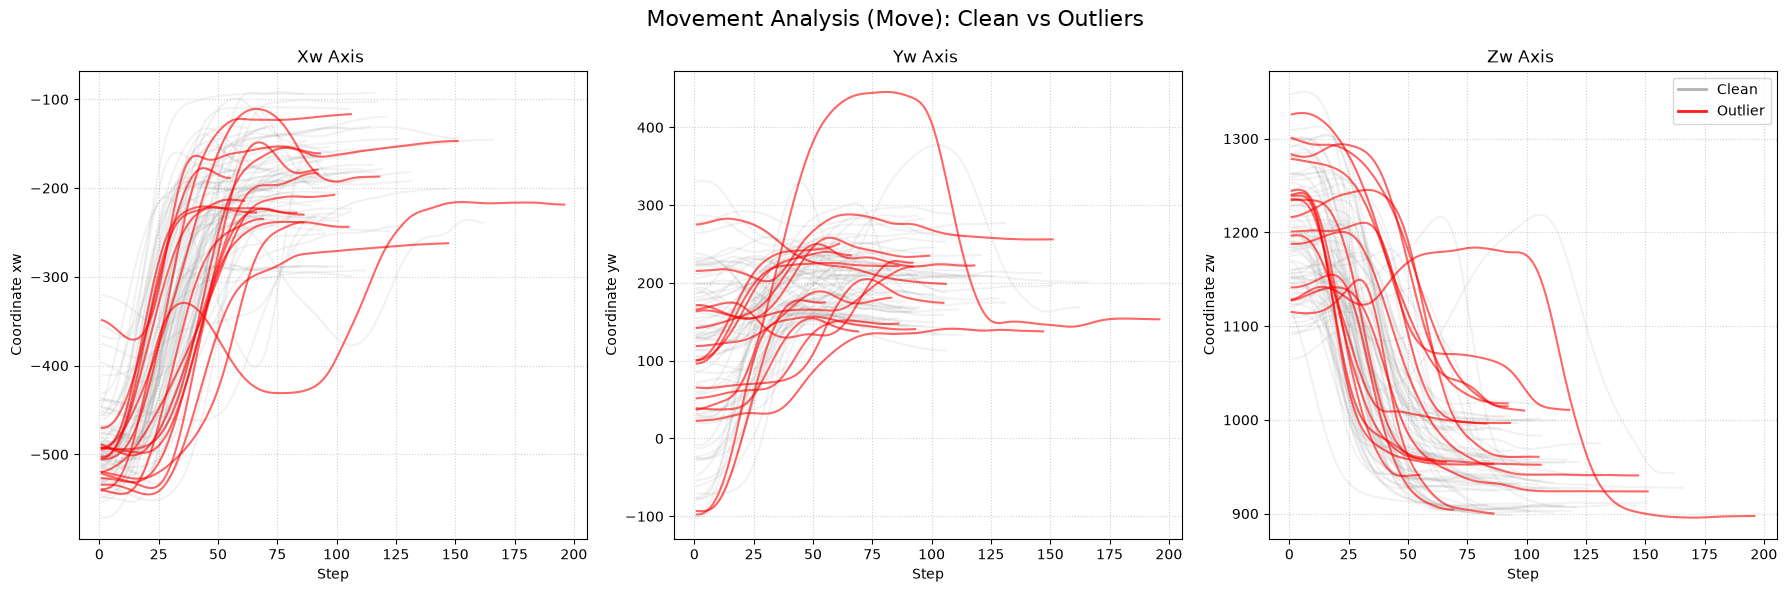

In [10]:
# ==========================================
# DIAGNÓSTICO E VISUALIZAÇÃO DE CONFIGURAÇÃO
# ==========================================

TARGET_MOV = 'Move'

if TARGET_MOV == 'Pick':
    inliers_temp = df_inliers_pick.copy()
elif TARGET_MOV == 'Move':
    inliers_temp = df_inliers_move.copy()
elif TARGET_MOV == 'Place':
    inliers_temp = df_inliers_place.copy()
else:
    inliers_temp = df_inliers_move.copy()

# Criar a chave 'temp_key' para agrupar as séries temporais nos inliers
inliers_temp['temp_key'] = inliers_temp['sub'].astype(str) + "_" + \
                           inliers_temp['repID'].astype(str) + "_" + \
                           inliers_temp['movID'].astype(str)

# 3. EXTRAIR OS OUTLIERS VERDADEIROS
# Vamos ao teu DataFrame original ('df' que carregou o filtered_data.csv completo)
df_original_mov = df[df['movLabel'] == TARGET_MOV].copy()

# Criar a mesma chave 'temp_key' no DataFrame original
df_original_mov['temp_key'] = df_original_mov['sub'].astype(str) + "_" + \
                              df_original_mov['repID'].astype(str) + "_" + \
                              df_original_mov['movID'].astype(str)

# Os outliers detetados são as linhas que estão no original mas NÃO estão nos inliers limpos
outliers_temp = df_original_mov[~df_original_mov['temp_key'].isin(inliers_temp['temp_key'])].copy()

print(f"--- Configuração do Gráfico para {TARGET_MOV} ---")
print(f"Linhas de Inliers (Trajetórias Normais): {len(inliers_temp)}")
print(f"Linhas de Outliers Detetados (Vão aparecer a Vermelho): {len(outliers_temp)}")

plot_movement_data(
    clean_data=inliers_temp,
    outlier_data=outliers_temp,
    target_movement=TARGET_MOV,  
    axis_names=['xw', 'yw', 'zw'] # Somente os pontos da mão
)

In [11]:
df_inliers_pick.head()

,sub,repID,movID,movType,step,movLabel,xs,ys,zs,xe,ye,ze,xw,yw,zw,vel,acc,t,k,jerk
0,6,1,1,0,1,Pick,-19.416119,191.445720,1455.119161,-73.768601,205.853671,1143.174685,-187.534286,217.491546,910.599346,0.012873,0.021275,-0.172269,2.697837,0.000000
1,6,1,1,0,2,Pick,-19.508986,191.468112,1455.089650,-73.879769,205.854552,1143.146713,-187.742206,217.435138,910.603327,0.012939,0.039943,-0.465353,4.939217,0.018667
2,6,1,1,0,3,Pick,-19.554322,191.505035,1455.042424,-73.990135,205.936455,1143.112378,-187.957126,217.420031,910.602861,0.013292,0.074186,-1.444924,8.564583,0.034243
3,6,1,1,0,4,Pick,-19.558498,191.555501,1454.978893,-74.102149,206.089674,1143.072063,-188.185726,217.436719,910.601448,0.014188,0.103099,-3.299226,10.266306,0.028913
4,6,1,1,0,5,Pick,-19.527886,191.618522,1454.900466,-74.218261,206.304506,1143.026154,-188.434688,217.475693,910.602585,0.015738,0.125656,-6.755100,9.310180,0.022558


## Remover série inteira do outlier (todo o RepID)
Caso não queira remover todo o RepID é só não correr este primeiro bloco de código

In [12]:
# =========================================================================
# PASSO 4: A GRANDE UNIÃO (Identificar os Outliers Globais do Modelo)
# =========================================================================

# 1. Obter as chaves originais de todas as repetições (por movimento)
keys_pick = df[df['movLabel'] == 'Pick'][['sub', 'repID']].drop_duplicates()
keys_move = df[df['movLabel'] == 'Move'][['sub', 'repID']].drop_duplicates()
keys_place = df[df['movLabel'] == 'Place'][['sub', 'repID']].drop_duplicates()

# 2. Obter as chaves dos Inliers que sobreviveram ao teu algoritmo UMAP
# (Usamos um DataFrame vazio de segurança caso o ficheiro falhe)
inliers_pick = df_inliers_pick[['sub', 'repID']].drop_duplicates() if df_inliers_pick is not None else pd.DataFrame(columns=['sub', 'repID'])
inliers_move = df_inliers_move[['sub', 'repID']].drop_duplicates() if df_inliers_move is not None else pd.DataFrame(columns=['sub', 'repID'])
inliers_place = df_inliers_place[['sub', 'repID']].drop_duplicates() if df_inliers_place is not None else pd.DataFrame(columns=['sub', 'repID'])

# 3. Descobrir quem foi detetado como Outlier em cada fase (Anti-Join)
# As anomalias são as repetições que estão nas chaves originais, mas NÃO estão nos inliers!
outliers_pick = pd.merge(keys_pick, inliers_pick, on=['sub', 'repID'], how='left', indicator=True)
outliers_pick = outliers_pick[outliers_pick['_merge'] == 'left_only'].drop(columns=['_merge'])

outliers_move = pd.merge(keys_move, inliers_move, on=['sub', 'repID'], how='left', indicator=True)
outliers_move = outliers_move[outliers_move['_merge'] == 'left_only'].drop(columns=['_merge'])

outliers_place = pd.merge(keys_place, inliers_place, on=['sub', 'repID'], how='left', indicator=True)
outliers_place = outliers_place[outliers_place['_merge'] == 'left_only'].drop(columns=['_merge'])

# 4. A Grande União: Juntar todas as anomalias e remover duplicados
# Se o Sujeito 2 falhou no Pick e no Place da mesma repetição, conta apenas como 1 erro.
outliers_globais_modelo = pd.concat([outliers_pick, outliers_move, outliers_place]).drop_duplicates()

print(f"\n--- RESULTADO DA GRANDE UNIÃO ---")
print(f"Outliers detetados pelo algoritmo no Pick: {len(outliers_pick)}")
print(f"Outliers detetados pelo algoritmo no Move: {len(outliers_move)}")
print(f"Outliers detetados pelo algoritmo no Place: {len(outliers_place)}")
print(f"Total de Repetições na Lista Negra Global: {len(outliers_globais_modelo)}")


--- RESULTADO DA GRANDE UNIÃO ---
Outliers detetados pelo algoritmo no Pick: 0
Outliers detetados pelo algoritmo no Move: 17
Outliers detetados pelo algoritmo no Place: 0
Total de Repetições na Lista Negra Global: 17


In [13]:
# =========================================================================
# PASSO 5: A GUILHOTINA (Criar o Dataset Ouro)
# =========================================================================
print("\n--- APLICANDO A GUILHOTINA ---")

# Fazer o Anti-Join da Lista Negra Global com o Dataset Bimanual original completo
df_guilhotina = pd.merge(df, outliers_globais_modelo, on=['sub', 'repID'], how='left', indicator=True)

# Manter APENAS as linhas limpas (que não estão na lista negra)
df_gold_standard = df_guilhotina[df_guilhotina['_merge'] == 'left_only'].drop(columns=['_merge'])

print(f"Linhas antes da Guilhotina: {len(df)}")
print(f"Linhas DEPOIS da Guilhotina: {len(df_gold_standard)}")
print(f"✅ Dataset de Ouro (Inliers perfeitos) pronto a usar para ensinar o Robô!")


--- APLICANDO A GUILHOTINA ---
Linhas antes da Guilhotina: 90333
Linhas DEPOIS da Guilhotina: 74082
✅ Dataset de Ouro (Inliers perfeitos) pronto a usar para ensinar o Robô!


### Export to csv

In [14]:
# =========================================================================
# PASSO 6: FORMATAÇÃO E EXPORTAÇÃO POR SUJEITO (Dataset de Ouro)
# =========================================================================
print("\n--- A FORMATAR E EXPORTAR FICHEIROS POR SUJEITO ---")

sensor_cols = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
colunas_pedidas = ['sub', 'repID', 'movID', 'movType', 'step'] + sensor_cols + ['vel', 'acc', 't', 'k']

# 2. Garantir que usamos apenas as colunas disponíveis no df_gold_standard
colunas_finais = [col for col in colunas_pedidas if col in df_gold_standard.columns]
df_final = df_gold_standard[colunas_finais].copy()

# 3. CORREÇÃO DE TIPOS: Garantir que os identificadores não ficam como decimais (ex: 1.0) devido ao Anti-Join
colunas_para_inteiro = ['sub', 'repID', 'movID', 'movType', 'step']
for col in colunas_para_inteiro:
    if col in df_final.columns:
        df_final[col] = df_final[col].astype(int)

# 4. Ordenação Cronológica Absoluta
df_final = df_final.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)

output_dir = Configs.ALL_SENSORS_FINAL_INLIERS
os.makedirs(output_dir, exist_ok=True)

sujeitos_exportados = 0
for subject in df_final['sub'].unique():
    df_subject = df_final[df_final['sub'] == subject]
    filename = f"Subject{int(subject)}Tasks.csv"
    filepath = os.path.join(output_dir, filename)
    df_subject.to_csv(filepath, index=False)
    sujeitos_exportados += 1

print(f"✅ Exportação Concluída! Foram gerados os ficheiros limpos para {sujeitos_exportados} sujeitos.")


--- A FORMATAR E EXPORTAR FICHEIROS POR SUJEITO ---
✅ Exportação Concluída! Foram gerados os ficheiros limpos para 19 sujeitos.
